In [40]:
#Import Julia packages
using XLSX
using PyPlot #To plot results
using FastaIO
using Statistics #For mean values using Random
using NaNStatistics #To make avareges over windows
using DelimitedFiles
using StatsBase
using CSV #to read CSV files
using Serialization #To write or read file ".bin"
using Revise #To include julia files with functions needed to run the notebook
using HTTP
using CodecZlib
using DataFrames

### Including Files

In [41]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [42]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets
includet(correct_path(split(pwd(), '/'), "Functions/IAV Functions.jl")) #To assess performance over IAV dataset

### Train Dataset

In [43]:
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
#Saving all the gene labels for the three datasets
gene_train=keys(train);

#### Trained models

In [44]:
#Importing models trained on GLORI HEK293T human cell line
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

#### Distibution of motives (train-set):

In [45]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)  # d(x(s̄_T)|m)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0); # d(x(s̄_T)|m̄)

#### Motifs Dictionaries

In [46]:
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];
Dict_RAC=Dict()
Dict_RAC["GAC"],Dict_RAC["AAC"]=[],[];

### Mapping IAV data from original to reference

In [47]:
Duck=readfasta((correct_path(split(pwd(), '/'), "/Additional Files/NCBI NCXJ16.fasta")));
xlsx = XLSX.readxlsx(correct_path(split(pwd(), '/'), "/Additional Files/methylation map pnas.2411554122.sd01.xlsx"))
# Access a specific sheet (there is only one sheet)
sheet = xlsx["Dataset S1"]
# Read data from a cell range, conserning the data needed:
data = sheet["B4:H125"] ;
#Saving segment names
Seg_name=["PB2", "PB1", "PA", "HA", "NP", "NA", "M", "NS"];
#Indexes of the excel columns needed to be save for the wanted information: segment name, strand, methylated position and motif
indexes=[1,5,6,7];
data_struct=[create_m6A(indexes, data, i) for i in 1:size(data)[1]];
# We divide the data in both positive and negative strand
positive_strand,negative_strand=[],[]
[(data_struct[i].strand =="+" ? push!(positive_strand, data_struct[i]) : push!(negative_strand, data_struct[i]))  for i in 1:length(data_struct)];
#Now we divide datasets based collecting m6A data based on the 8 IAV segments
supp_vec_p,supp_vec_n=[[],[],[],[],[],[],[],[]],[[],[],[],[],[],[],[],[]] #Empty collections of vector of length 8 (as long as the IAV segments)
[push!(supp_vec_n[negative_strand[i].segment], negative_strand[i]) for i in 1:length(negative_strand)];
PB2_n, PB1_n, PA_n, HA_n, NP_n, NA_n, M_n, NS_n=supp_vec_n[1],supp_vec_n[2],supp_vec_n[3],supp_vec_n[4],supp_vec_n[5],supp_vec_n[6], supp_vec_n[7],supp_vec_n[8];
[push!(supp_vec_p[positive_strand[i].segment], positive_strand[i]) for i in 1:length(positive_strand)];
PB2_p, PB1_p, PA_p, HA_p, NP_p, NA_p, M_p, NS_p=supp_vec_p[1],supp_vec_p[2],supp_vec_p[3],supp_vec_p[4],supp_vec_p[5],supp_vec_p[6], supp_vec_p[7],supp_vec_p[8];
#Collecting all psoitive and negative motifs in the created datasets (independently of the IAV segment)
train_met_p=[positive_strand[i].sequence for i in 1:length(positive_strand)];
train_met_n=[negative_strand[i].sequence for i in 1:length(negative_strand)];
#Saving all sequences
Seqs=[PB2_p,PB1_p, PA_p,HA_p,NP_p,NA_p,M_p, NS_p]; #+sstr
Seqs_n=[PB2_n,PB1_n, PA_n,HA_n,NP_n,NA_n,M_n, NS_n];#-sstr

In [48]:
#Finding the substring from Goose SC15 into Duck SC14
Dictionary_m6A=[find_string(Duck[ind][2], Seqs[ind]) for ind in 1:8]
#Saving the position methylation found in +sstr
pos_met=[[vcat(values(Dictionary_m6A[ind])...)[j][1] for j in 1:length(Dictionary_m6A[ind])] for ind in 1:8];
#Considering the negative strand we repeate the same procedure to map methylated sites
Duck_n=cmp_inv_IAV(Duck); #before we need to consider the viral genomes (inverse complement of mRNA)
#Finding the substring from Goose SC15 into Duck SC14 in the negative strand
Dictionary_m6A_n=[find_string(Duck_n[ind][2], Seqs_n[ind]) for ind in 1:8]
#Saving the position methylation found in -sstr
pos_met_n=[[vcat(values(Dictionary_m6A_n[ind])...)[j][1] for j in 1:length(Dictionary_m6A_n[ind])] for ind in 1:8];

### Positive strand (+sstr)

In [49]:
#joining all segments to form a single mRNA
full_seq=""
for i in [1, 2, 4, 5, 8] #looping over the set of +sstr testing segemnts
full_seq*=Duck[i][2]
end
LL=[] #initialization for the vector containing the lengths of the testing segments
[push!(LL, length(Duck[i][2])) for i in [1,2,4,5,8]]
pos_all=[]
push!(pos_all, pos_met[1])
io=[2, 4, 5, 8]
#Adding all the position of the segments with respect to the full sequence
[push!(pos_all, pos_met[io[i]].+sum(LL[1:i])) for i in 1:length(io)]
#joining all elements
pos_all=vcat(pos_all...);
#initialization of a null vector
pos_vec=vcat(zeros(1, length(full_seq))...)
#setting to 1 all the positions of mapped methylated motifs
[pos_vec[p]=1.0 for p in pos_all];

### Negative strand: -sstr (vRNA)

In [50]:
#joining all segments to form a single vRNA
full_seq_n=""
for i in 1:8
    full_seq_n*=Duck_n[i][2] 
end
#initialization for the vector containing the lengths of the testing segments
LLn=[]
[push!(LLn, length(Duck[i][2])) for i in 1:8]
pos_all_n=[]
push!(pos_all_n, pos_met_n[1])
#Adding all the position of the segments with respect to the full sequence
[push!(pos_all_n, pos_met_n[i].+sum(LLn[1:i-1])) for i in 2:8]
#joining all elements
pos_all_n=vcat(pos_all_n...);

### IAV prior

In [51]:
#Saving the sequence Puerto Rico 8 1934 H1N1 for the prior
PR8=readfasta((correct_path(split(pwd(), '/'), "/Additional Files/NCBI PR8.fasta")));
#Data of the experimental peak m6A in IAV PR8
file_annotations_rna=HTTP.get("https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM2585819&format=file&file=GSM2585819%5FPR8%2Dm6A%2Dseq%5FPOS%2Ebed%2Egz");
Dataset_PR8=CSV.read(file_annotations_rna.body,DataFrame, header=false);

For the computation of the IAV constant prior, we consider the following expression:

$$p_0^{IAV}(m)=\frac{1}{8}\cdot \bigg(3 p_0^{PA}(m)+2p_0^{NA}(m)+3p_0^{M}(m) \bigg)$$

In [52]:
ww=[3,2, 3] #weights associated to each class
av=sum([(length(pos_met[i])/(count('A', Duck[i][2]))) for i in [3,6,7]].*ww)/8 ;

For the computation of the transcript-dependent prior we consider a peak experiment with a different sequence. The equation generalize as follows:

$$p_0^{T_i, IAV}(m)=\frac{p_0^IAV(m)}{\mathcal{P}}\cdot \mathcal{P}_i$$

where the two quantities represent the normalized area of the methylation signal per segment, and the total normalized area:


$$\mathcal{P}_i=\frac{1}{L_i}\sum_{j=1}^{L_i}peak(j) \ / \  \mathcal{P}=\sum_{i=1}^8 \mathcal{P}_i$$

In [53]:
#joining all segments for a single RNDataset_PR8 sequence for IDataset_PR8V PR8
full_PR8=""
for i in 1:8
    full_PR8*=PR8[i][2] 
end
L8=[] #initialization for the vector containing the lengths of segments for the prior
push!(L8, length(PR8[1][2]))
[push!(L8, sum(L8[end])+length(PR8[i][2])) for i in 2:8]
Lini8=[] #initialization for the vector containing the initial lengths of the testing segments
push!(Lini8, 1)
[push!(Lini8, L8[i]+1) for i in 1:7]
S=[] #initialization empty vector
res=vcat(zeros(1, length(full_PR8))...); #intiialization of zeros
for ind in 1:8 #looping over all the segments
    s=0
    for i in 1:size(Dataset_PR8)[1]
        if i%1==0 #the information of the peak curve is every two lines of the file 
            if Dataset_PR8[i,2]>=Lini8[ind] && Dataset_PR8[i,3]<=L8[ind] #if the range in the file is between a segment length
                res[Dataset_PR8[i, 2]:Dataset_PR8[i, 3]].+=Dataset_PR8[i, 4] #the coverage is addete
                s+= Dataset_PR8[i, 4]/(length(PR8[ind][2])) #additing to compute the area under the curve normalized covergae by the segment length
            end
        end
    end
    push!(S,s)
end
M0=S./sum(S);
MM=av/mean(M0).*M0;

### Adding the modulation by m6A distribution  

In [54]:
#Saving all the CDS regions (from NCBI annotations) relatively to the sequence A/Duck
CDS_IAV=[[1,2280],[1,2274], [1,760] , [1,1704], [1, 1497], [1,1413], [1, 759], [1,678]];

Creating a structure of type info_IAV, containing all the infromation relative to each influenza segments and their methylation 

In [55]:
IAV=Dict()
for i in 1:8 
    p=pos_met[i]
    u=setdiff!(findall('A',Duck[i][2] ), p)
    IAV[Seg_name[i]]=info_IAV(
        Duck[i][2], #Saving the sequence
        CDS(CDS_IAV[i][1],CDS_IAV[i][2] ), #Converting START and STOP codon into CDS structure
        p, #position of all methylated sites
        u, #position of all non-methylated sites
        100*(length(p)/(length(p)+length(u))) #percentage of methylated sites in the sequence
    )
end

In [56]:
#Mapping all the positions of the sequences into a metage profile made by 1/3 5'-UTR, 
#1/3 CDS and 1/3 3'-UTR.
MAP_IAV=mapping_position(IAV, Seg_name);

In [57]:
#Setting the treshold value to distinguish methylated and non-methylated motifs from
#the treshold corresponding to the maximum F1 value over a validation set in GLORI-seq data from fuman HEK293T cell line
TRE=0.225;

#### Scoring MEMAR-XT: +sstr

In [58]:
score_pos=vcat([score_genome_complete(M5, M6,  MM[i],Duck[i][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[i]) for i in [1,2,4,5,8]]...);

#### Scoring MEMAR-T: -sstr

In [59]:
score_neg=vcat([score_genome_complete(M5, M6,  MM[i],Duck_n[i][2], 8; verbose=false) for i in 1:8]...);

### DeepSRAMP

In [60]:
D_PB2, P_PB2=eachcol(CSV.read(correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PB2 positive strand.csv"), DataFrame))
D_PB1, P_PB1=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PB1 positive strand.csv"), DataFrame))
D_PA, P_PA=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PA positive strand.csv"), DataFrame))
D_HA, P_HA=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP HA positive strand.csv"), DataFrame))
D_NP, P_NP=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NP positive strand.csv"), DataFrame))
D_NA, P_NA=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NA positive strand.csv"), DataFrame))
D_M, P_M=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP M positive strand.csv"), DataFrame))
D_NS, P_NS=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NS positive strand.csv"), DataFrame));

In [61]:
CSV.read( "DeepSRAMP PB2 negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP PB1 negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP PA negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP HA negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP NP negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP NA negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP M negative strand.csv", DataFrame)
CSV.read( "DeepSRAMP NS negative strand.csv", DataFrame)

ArgumentError: ArgumentError: "DeepSRAMP PB2 negative strand.csv" is not a valid file or doesn't exist

In [62]:
D_D=[D_PB2,D_PB1, D_HA, D_NP,  D_NS]
P_P=[P_PB2, P_PB1, P_HA, P_NP, P_NS];
P_FULL=vcat(P_P...);
D_FULL=[]
push!(D_FULL, D_D[1])
for i in 2:length(D_D)
    push!(D_FULL, D_D[i].+sum(LL[1:i-1]))
end
D_FULL=vcat(D_FULL...);
score_Deep=zeros(length(full_seq))
[score_Deep[D_FULL[i]+1]=P_FULL[i] for i in 1:length(P_FULL)];

In [63]:
D_D_2=[D_PB2,D_PB1, D_PA,D_HA, D_NP,D_NA, D_M, D_NS]
P_P_2=[P_PB2, P_PB1, P_PA,P_HA, P_NP,P_NA,P_M, P_NS];

In [64]:
D_PB2_n, P_PB2_n=eachcol(CSV.read(correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PB2 negative strand.csv"), DataFrame))
D_PB1_n, P_PB1_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PB1 negative strand.csv"), DataFrame))
D_PA_n, P_PA_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP PA negative strand.csv"), DataFrame))
D_HA_n, P_HA_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP HA negative strand.csv"), DataFrame))
D_NP_n, P_NP_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NP negative strand.csv"), DataFrame))
D_NA_n, P_NA_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NA negative strand.csv"), DataFrame))
D_M_n, P_M_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP M negative strand.csv"), DataFrame))
D_NS_n, P_NS_n=eachcol(CSV.read( correct_path(split(pwd(), '/'),"Additional Files/DeepSRAMP NS negative strand.csv"), DataFrame));

In [65]:
D_D_n=[D_PB2_n,D_PB1_n, D_PA_n,D_HA_n, D_NP_n, D_NA_n,D_M_n, D_NS_n]
P_P_n=[P_PB2_n, P_PB1_n, P_PA_n,P_HA_n, P_NP_n,P_NA_n,P_M_n, P_NS_n];
P_FULL_n=vcat(P_P_n...);
D_FULL_n=[]

push!(D_FULL_n, D_D_n[1])
for i in 2:length(D_D_n)
    push!(D_FULL_n, D_D_n[i].+sum(LLn[1:i-1]))
end

D_FULL_n=vcat(D_FULL_n...);
score_Deep_n=zeros(length(full_seq_n))
[score_Deep_n[D_FULL_n[i]+1]=P_FULL_n[i] for i in 1:length(P_FULL_n)];

### PRC

F1 at treshold: (0.65, 0.796)
Imbalance: 28.436%
F1 at treshold: (0.467, 0.538)
Imbalance: 28.436%


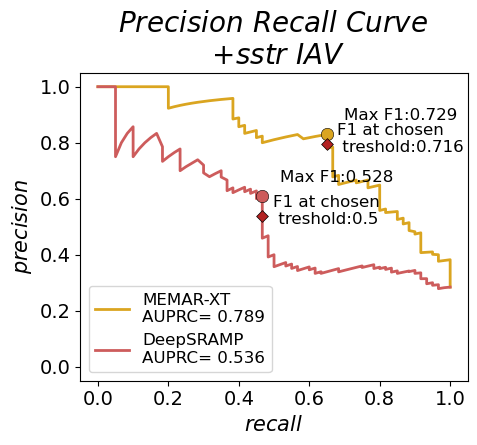

In [66]:
close("all")
figure(figsize=(5,4))
AUC_IAV(score_pos, pos_all,full_seq, TRE;  pass=0.001, c="goldenrod", legen="MEMAR-XT", Dict=Dict_DRACH, l=2)
AUC_IAV(score_Deep, pos_all,full_seq, 0.5;  pass=0.001, c="indianred", legen="DeepSRAMP", Dict=Dict_DRACH, l=2)
title("\$Precision \\ Recall \\ Curve\$ \n \$  +sstr \\ IAV \$", size=20)
gcf()

F1 at treshold: (0.455, 0.4)
Imbalance: 12.644%
F1 at treshold: (0.636, 0.173)
Imbalance: 12.644%


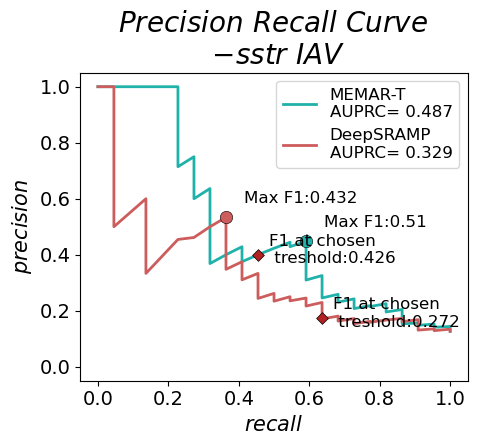

In [67]:
close("all")
figure(figsize=(5,4))
AUC_IAV(score_neg, pos_all_n,full_seq_n, TRE;  pass=0.001, c="lightseagreen", legen="MEMAR-T", Dict=Dict_DRACH, l=2)
AUC_IAV(score_Deep_n, pos_all_n,full_seq_n, 0.5;  pass=0.001, c="indianred", legen="DeepSRAMP", Dict=Dict_DRACH, l=2)
title("\$Precision \\ Recall \\ Curve\$ \n \$  -sstr \\ IAV \$", size=20)
gcf()

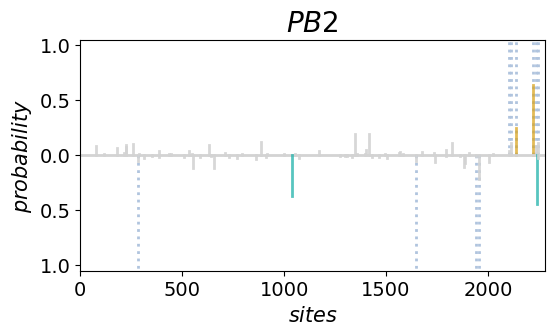

In [68]:
close("all")
#Chosen IAV segment to plot predictions
ind=1
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

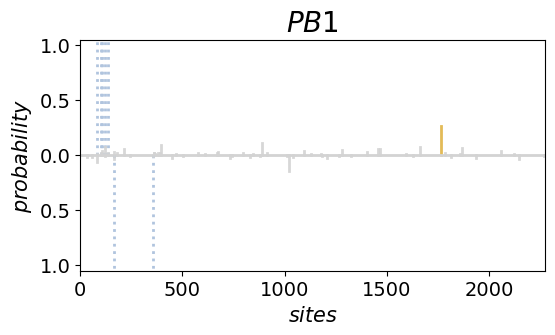

In [69]:
close("all")
#Chosen IAV segment to plot predictions
ind=2
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

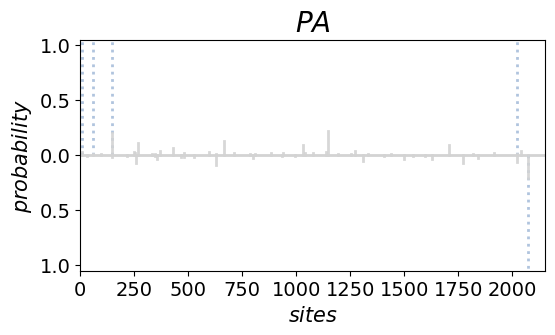

In [70]:
close("all")
#Chosen IAV segment to plot predictions
ind=3
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

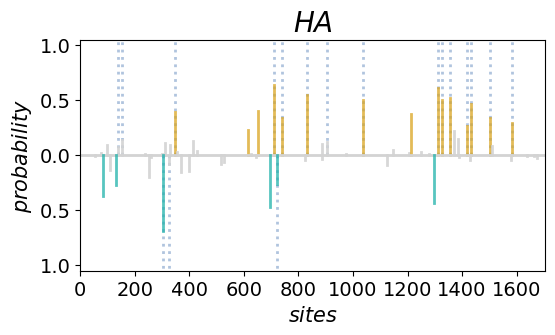

In [71]:
close("all")
#Chosen IAV segment to plot predictions
ind=4
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

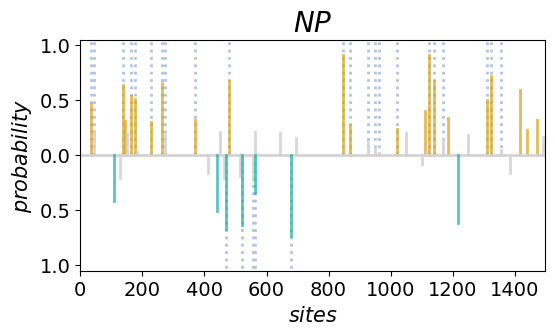

In [72]:
close("all")
#Chosen IAV segment to plot predictions
ind=5
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

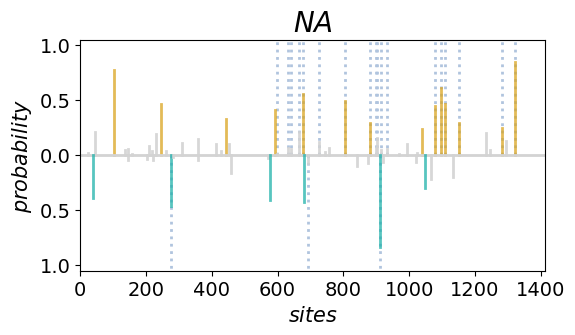

In [73]:
close("all")
#Chosen IAV segment to plot predictions
ind=6
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

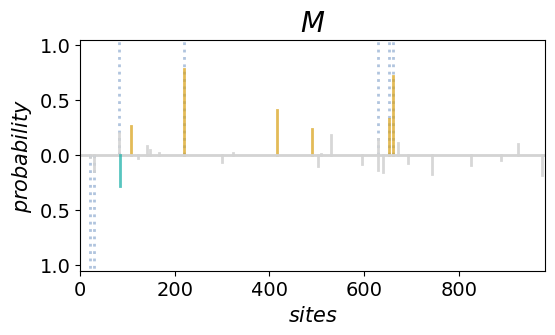

In [74]:
close("all")
#Chosen IAV segment to plot predictions
ind=7
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()

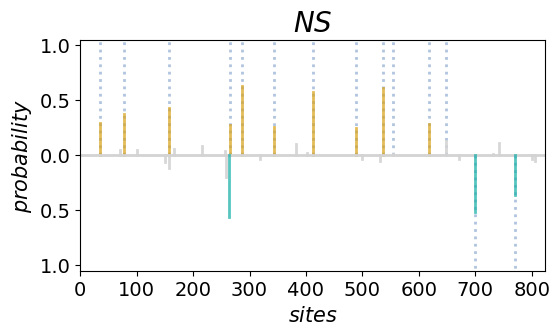

In [75]:
close("all")
#Chosen IAV segment to plot predictions
ind=8
#Positive strand plot: upper graph
score_pos_ind=score_genome_complete(M5, M6,  MM[ind],Duck[ind][2], 8; verbose=true, Mapping=MAP_IAV,  dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=Seg_name[ind])
plot_score(score_pos_ind, Duck[ind][2], pos_met[ind];  Dict_filtr=Dict_DRACH,ww=2, lw=2, sizes=(6,3), tresh=TRE)
#Negative strand plot: lower graph
score_neg_ind=score_genome_complete(M5, M6,  MM[ind],Duck_n[ind][2], 8; verbose=false)
plot_score_neg(score_neg_ind, Duck_n[ind][2], pos_met_n[ind];  Dict_filtr=Dict_DRACH,ww=2,lw=2, sizes=(7,3), tresh=TRE)
title("\$ $(Seg_name[ind])\$", size=20)
gcf()